# Kiosk sessions

The first cells run the discovery queries. They are the inventory, the grain, the session check, and the store list. The charts after them answer the question those tables leave open. The saved outputs were produced from the repo root.


In [1]:
%matplotlib inline
import html
import os
import re
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "sql" / "init_ddl.sql").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)

con = duckdb.connect()
con.execute((ROOT / "sql" / "init_ddl.sql").read_text())

TITLE = 14
POINT = 8
LEGEND = dict(
    fontsize=8,
    frameon=False,
    borderpad=0.3,
    labelspacing=0.3,
    handlelength=1.2,
    handletextpad=0.45,
)


def tenant_name(value):
    return str(value).replace("tenant_", "Tenant ")


def short_num(value):
    value = float(value)
    if abs(value) >= 1000:
        return f"{value / 1000:.1f}k"
    return f"{value:.0f}"


def polish(ax, title, xlabel=None, ylabel=None, grid="y"):
    ax.set_title(title, fontsize=TITLE, pad=10)
    ax.tick_params(labelsize=8)
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=9)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=9)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if grid == "y":
        ax.yaxis.grid(True, color="#E6E6E6", linewidth=0.6)
        ax.set_axisbelow(True)
    elif grid == "x":
        ax.xaxis.grid(True, color="#E6E6E6", linewidth=0.6)
        ax.set_axisbelow(True)


def point(ax, x, y, text, color="#1B2838", xytext=(0, 2), va="bottom", ha="center", bbox=None):
    ax.annotate(
        text,
        (x, y),
        textcoords="offset points",
        xytext=xytext,
        ha=ha,
        va=va,
        fontsize=POINT,
        color=color,
        bbox=bbox,
    )


pd.set_option("display.colheader_justify", "left")


class LeftTable(pd.DataFrame):
    def _repr_html_(self):
        head = "".join(
            f'<th style="text-align:left">{html.escape(str(col))}</th>' for col in self.columns
        )
        body = []
        for idx, row in self.iterrows():
            cells = "".join(
                f'<td style="text-align:left">{html.escape(str(value))}</td>' for value in row
            )
            body.append(
                f'<tr><th style="text-align:left">{html.escape(str(idx))}</th>{cells}</tr>'
            )
        return (
            '<table class="dataframe">'
            f'<thead><tr><th style="text-align:left"></th>{head}</tr></thead>'
            f"<tbody>{''.join(body)}</tbody></table>"
        )


def show_tenants(frame):
    out = frame.copy()
    if "tenant" in out.columns:
        out["tenant"] = out["tenant"].map(tenant_name)
    return out


def present(frame):
    out = show_tenants(frame)
    shown = pd.DataFrame(index=out.index)
    for col in out.columns:
        series = out[col]
        name = str(col).lower()
        money = "revenue" in name and "count" not in name and not name.startswith("unique_")
        if money:
            numeric = pd.to_numeric(series, errors="coerce")
            if int(numeric.notna().sum()) == int(series.notna().sum()):
                shown[col] = [
                    "" if pd.isna(value) else f"{float(value):.2f}" for value in numeric
                ]
                continue
        if pd.api.types.is_datetime64_any_dtype(series):
            shown[col] = series.dt.strftime("%Y-%m-%dT%H:%M:%S")
        else:
            shown[col] = ["" if pd.isna(value) else str(value) for value in series]
    return LeftTable(shown)


def sql_file(path):
    raw = (ROOT / path).read_text()
    raw = re.sub(r"/\*.*?\*/", "", raw, flags=re.S)
    frames = []
    for chunk in raw.split(";"):
        kept = [line for line in chunk.splitlines() if not line.strip().startswith("--")]
        statement = "\n".join(kept).strip()
        if statement:
            frames.append(present(con.sql(statement).df()))
    return frames


def load_identity():
    global identity, file_counts
    if "identity" not in globals():
        identity = con.sql("""
        SELECT
            session_id,
            MIN(tenant) AS tenant,
            MIN(store_id_unified) AS store,
            MIN(kiosk_id_up) AS kiosk,
            COUNT(DISTINCT tenant) AS tenants,
            COUNT(DISTINCT store_id_unified) AS stores,
            COUNT(DISTINCT kiosk_id_up) AS kiosks,
            COUNT(DISTINCT event_date) AS dates,
            MIN(event_date) AS first_date,
            MAX(event_date) AS last_date
        FROM events
        GROUP BY session_id
        """).df()
    if "file_counts" not in globals():
        file_counts = con.sql("""
        SELECT
            COUNT(*) AS rows,
            COUNT(*) - COUNT(DISTINCT session_id || '|' || CAST(event_index AS VARCHAR)) AS duplicate_pairs
        FROM events
        """).df()
    return identity, file_counts


def load_daily():
    global daily
    if "daily" not in globals():
        daily = con.sql("""
        SELECT
            event_date,
            tenant,
            COUNT(DISTINCT session_id) AS unique_sessions,
            SUM(item_revenue) AS total_item_revenue
        FROM events
        GROUP BY event_date, tenant
        ORDER BY event_date, tenant
        """).df()
    return daily


def load_session_flags():
    global session_flags
    if "session_flags" not in globals():
        session_flags = con.sql("""
        SELECT
            tenant,
            session_id,
            MIN(store_id_unified) AS store,
            MIN(kiosk_id_up) AS kiosk,
            MAX(event_name = 'view_item_list') AS viewed,
            MAX(event_name = 'select_item') AS selected,
            MAX(event_name = 'add_to_cart') AS carted,
            MAX(event_name = 'purchase') AS purchased,
            COUNT(*) FILTER (WHERE event_name = 'purchase') AS purchase_rows,
            COALESCE(SUM(item_revenue) FILTER (WHERE event_name = 'purchase'), 0) AS purchase_revenue
        FROM events
        GROUP BY tenant, session_id
        """).df()
    return session_flags


## What is in the file

`sql/discovery_query.sql`. The first table is the whole file. The second is the same counts by tenant. The revenue sum mixes price units, so it is not a ranking. Later charts do not compare tenants by that sum.


In [2]:
from IPython.display import display

for frame in sql_file("sql/discovery_query.sql"):
    display(frame)


,row_count,unique_tenants_count,unique_sessions_count,unique_event_names_count,unique_event_indexes_count,unique_stores_count,unique_kiosks_count,unique_items_count,non_null_rows_revenue_count,non_null_revenue_sum
0,1814373,2,36693,4,353,31,64,596,46176,1142573.67


,tenant,rows,sessions,unique_stores_count,unique_kiosks_count,unique_items_count,non_null_rows_revenue_count,non_null_revenue_sum,min_date,max_date
0,Tenant 1,1648005,32291,29,58,317,40936,440528.67,2026-04-17T00:00:00,2026-05-01T00:00:00
1,Tenant 2,166368,4402,2,6,279,5240,702045.00,2026-04-17T00:00:00,2026-05-01T00:00:00


## Whether a session stays in one place

`sql/discovery_grain.sql`. A row is one event. The first table counts duplicate `session_id` and `event_index` pairs: 46. The second table checks whether one session crosses a tenant, a store, a kiosk, or a date. None crosses a tenant, a store, or a kiosk. Nine sessions touch more than one date.


In [3]:
from IPython.display import display

for frame in sql_file("sql/discovery_grain.sql"):
    display(frame)


,row_count,distinct_session_event_index,duplicate_pairs
0,1814373,1814327,46


,check_name,sessions_with_multiple
0,tenants_per_session,0
1,stores_per_session,0
2,kiosks_per_session,0
3,dates_per_session,9


## A session is one visit

`sql/discovery_session_identity.sql`. Nine sessions touch more than one date, and the longest span is one day. There is no guest id, so a session is one visit, not a customer who comes back. The daily table is the base for the next chart. Its revenue column is still not a cross-tenant ranking.


In [4]:
from IPython.display import display

for frame in sql_file("sql/discovery_session_identity.sql"):
    display(frame)


,sessions,sessions_spanning_multiple_dates,max_day_span
0,36693,9,1


,event_date,tenant,event_rows,unique_sessions,unique_item_revenues,total_item_revenue
0,2026-04-17T00:00:00,Tenant 1,147284,2940,308,40553.94
1,2026-04-17T00:00:00,Tenant 2,13848,375,60,61182.00
2,2026-04-18T00:00:00,Tenant 1,132150,2518,337,37408.17
3,2026-04-18T00:00:00,Tenant 2,9562,242,62,39802.00
4,2026-04-19T00:00:00,Tenant 1,107556,2076,283,29822.56
5,2026-04-19T00:00:00,Tenant 2,10965,282,61,55412.00
6,2026-04-20T00:00:00,Tenant 1,97161,1891,251,23542.40
7,2026-04-20T00:00:00,Tenant 2,12152,309,58,53920.00
8,2026-04-21T00:00:00,Tenant 1,99520,1954,269,24653.04
9,2026-04-21T00:00:00,Tenant 2,10577,289,61,33913.00


## Stores, kiosks, and raw revenue

`sql/discovery_kiosk_stores.sql`. One row per kiosk, then one row per store. Raw revenue sorts Tenant 2's stores first because the price unit is different. The last result lists kiosks that sit in more than one store. An empty table means that count is zero.


In [5]:
from IPython.display import display

for frame in sql_file("sql/discovery_kiosk_stores.sql"):
    display(frame)
    if frame.empty:
        print("0 rows. No kiosk sits in more than one store.")


,tenant,store_id_unified,kiosk_id_up
0,Tenant 1,11330,19685
1,Tenant 1,11330,19686
2,Tenant 1,11478,19625
3,Tenant 1,11478,19626
4,Tenant 1,11598,19543
5,Tenant 1,11598,19544
6,Tenant 1,11599,19598
7,Tenant 1,11599,19599
8,Tenant 1,12321,24356
9,Tenant 1,12321,24357


,tenant,store_id_unified,kiosk_id_up_count,avg_item_revenue,total_item_revenue
0,Tenant 1,2516,3,9.68,37215.57
1,Tenant 1,14343,2,10.38,36402.05
2,Tenant 1,15644,3,10.84,29249.37
3,Tenant 1,16053,2,9.68,23751.79
4,Tenant 1,15866,2,11.75,23471.96
5,Tenant 1,15109,2,10.34,22090.55
6,Tenant 1,15445,2,10.60,20636.60
7,Tenant 1,15682,2,10.96,19480.30
8,Tenant 1,15348,2,11.99,18299.19
9,Tenant 1,11598,2,10.12,17443.93


,kiosk_id_up_count


0 rows. No kiosk sits in more than one store.


## The gap holds on every day

The tenant table shows Tenant 1 has far more sessions. This chart asks whether that is true on every day, or only on a few busy days.


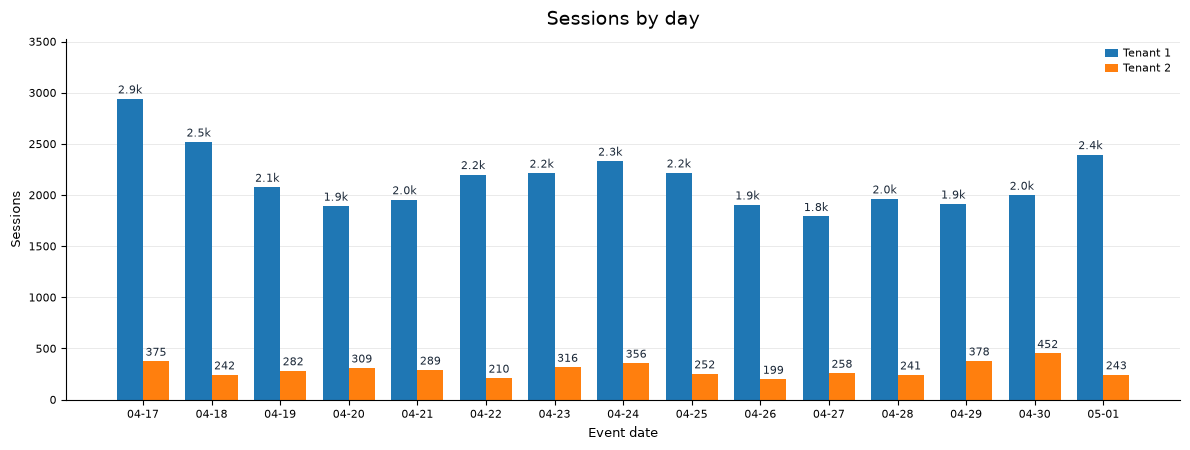

In [6]:
import numpy as np

daily = load_daily()
frame = daily.copy()
frame["day"] = frame["event_date"].dt.normalize()
dates = list(frame["day"].drop_duplicates().sort_values())
tenants = sorted(frame["tenant"].unique())
x = np.arange(len(dates))
width = 0.38

fig, ax = plt.subplots(figsize=(12, 4.6))
peak = 0
series = []
for tenant in tenants:
    values = (
        frame.loc[frame["tenant"] == tenant]
        .set_index("day")
        .reindex(dates)["unique_sessions"]
        .fillna(0)
        .to_numpy(dtype=float)
    )
    series.append(values)
    peak = max(peak, float(values.max()))
for i, (tenant, values) in enumerate(zip(tenants, series)):
    bars = ax.bar(
        x + (i - 0.5) * width,
        values,
        width,
        label=tenant_name(tenant),
        color=f"C{i}",
    )
    other = series[1 - i] if len(series) == 2 else None
    for j, (bar, value) in enumerate(zip(bars, values)):
        close = other is not None and abs(value - other[j]) < peak * 0.06
        point(
            ax,
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            short_num(value),
            xytext=(0, 9 if close and i else 2),
        )
ax.set_xticks(x)
ax.set_xticklabels([day.strftime("%m-%d") for day in dates])
ax.set_ylim(0, peak * 1.2)
polish(ax, "Sessions by day", xlabel="Event date", ylabel="Sessions")
ax.legend(loc="upper right", **LEGEND)
fig.tight_layout()
plt.show()


## Most visits reach a purchase

A session counts at a step when it has that event at least once. The top line is the step. The bottom line is the count, then the share of all sessions. Those labels are the true shares. The drawing uses an even taper unless `PROPORTIONAL` is turned on, so the band widths are not the shares. Set `PROPORTIONAL = True` to draw the widths from the session counts. That taper stays shallow, because most sessions reach a purchase.


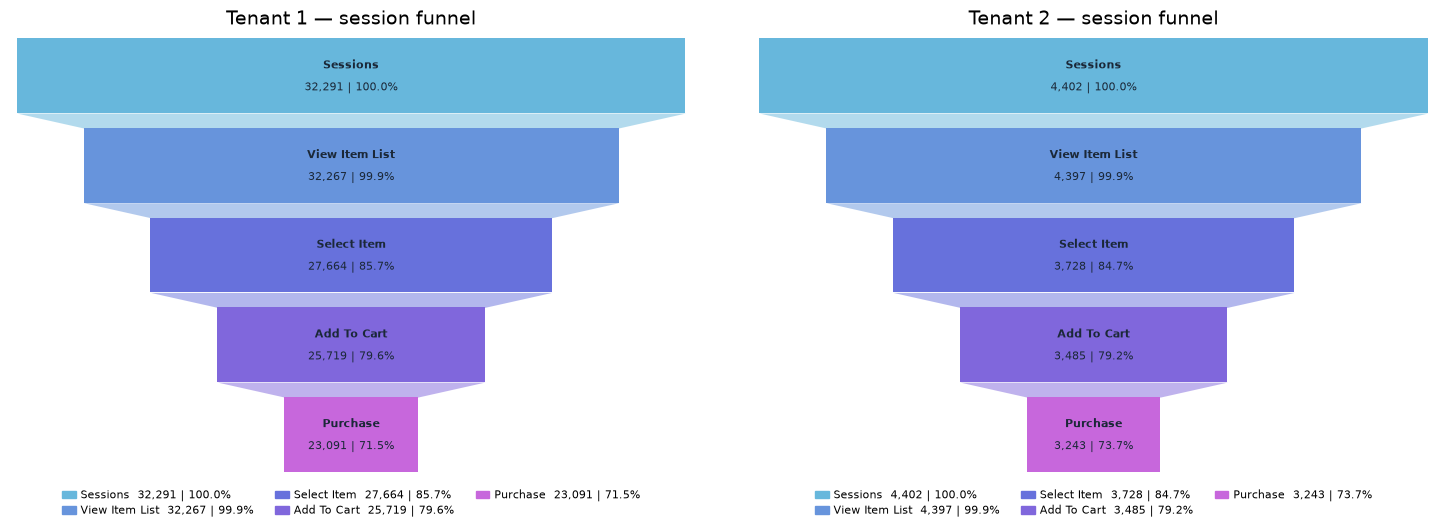

In [7]:
from matplotlib.patches import Patch

session_flags = load_session_flags()
funnel = (
    session_flags.groupby("tenant", as_index=False)
    .agg(
        sessions=("session_id", "size"),
        viewed=("viewed", "sum"),
        selected=("selected", "sum"),
        carted=("carted", "sum"),
        purchased=("purchased", "sum"),
    )
    .sort_values("tenant")
)

stages = ["sessions", "view_item_list", "select_item", "add_to_cart", "purchase"]
columns = ["sessions", "viewed", "selected", "carted", "purchased"]
colors = ["#67B7DC", "#6794DC", "#6771DC", "#8067DC", "#C767DC"]
# False keeps an even taper. True uses the session counts, and the taper stays shallow.
PROPORTIONAL = False


def draw_funnel(ax, labels, values):
    n = len(values)
    if PROPORTIONAL:
        half = [value / values[0] for value in values]
    else:
        half = [1 - i * (0.8 / (n - 1)) for i in range(n)]
    body, neck = 1.0, 0.2
    y = n * body + (n - 1) * neck
    handles = []
    for i, (label, value, color) in enumerate(zip(labels, values, colors)):
        share = 100 * value / values[0]
        y_top = y
        y_body = y_top - body
        ax.fill_betweenx([y_body, y_top], -half[i], half[i], color=color, linewidth=0)
        if i < n - 1:
            y_bot = y_body - neck
            ax.fill_betweenx(
                [y_bot, y_body],
                [-half[i + 1], -half[i]],
                [half[i + 1], half[i]],
                color=color,
                alpha=0.5,
                linewidth=0,
            )
            y = y_bot
        mid = (y_top + y_body) / 2
        name = label.replace("_", " ").title()
        ax.text(0, mid + 0.14, name, ha="center", va="center", fontsize=POINT, fontweight="bold", color="#1B2838", clip_on=True)
        ax.text(0, mid - 0.16, f"{value:,} | {share:.1f}%", ha="center", va="center", fontsize=POINT, color="#1B2838", clip_on=True)
        handles.append(Patch(color=color, label=f"{name}  {value:,} | {share:.1f}%"))
    ax.set_xlim(-1.02, 1.02)
    ax.set_ylim(0, n * body + (n - 1) * neck)
    ax.set_axis_off()
    ax.legend(
        handles=handles,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.02),
        ncol=3,
        handleheight=0.7,
        **LEGEND,
    )


tenants = list(funnel["tenant"])
fig, axes = plt.subplots(1, len(tenants), figsize=(7.5 * len(tenants), 5.4))
if len(tenants) == 1:
    axes = [axes]
for ax, tenant in zip(axes, tenants):
    row = funnel.loc[funnel["tenant"] == tenant].iloc[0]
    counts = [int(row[column]) for column in columns]
    draw_funnel(ax, stages, counts)
    ax.set_title(f"{tenant_name(tenant)} — session funnel", fontsize=TITLE, pad=10)
fig.tight_layout()
plt.show()


## Where the sessions are lost

The funnel shows who remains. This chart shows who is lost at each handoff, as a percent of the sessions that reached the step before it. Both tenants lose the most between view and select. Tenant 1 loses more between cart and purchase.


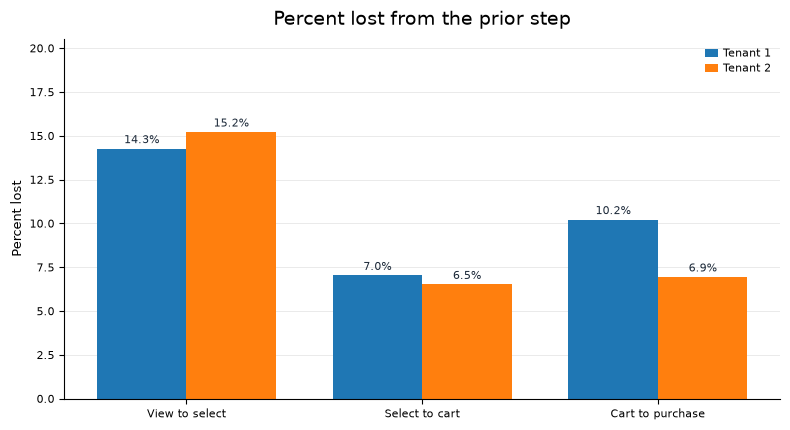

In [8]:
import numpy as np

session_flags = load_session_flags()
steps = [
    ("View to select", "selected", "viewed"),
    ("Select to cart", "carted", "selected"),
    ("Cart to purchase", "purchased", "carted"),
]
tenants = sorted(session_flags["tenant"].unique())
x = np.arange(len(steps))
width = 0.38
fig, ax = plt.subplots(figsize=(8, 4.4))
peak = 0
for i, tenant in enumerate(tenants):
    frame = session_flags.loc[session_flags["tenant"] == tenant]
    lost = [100 * (1 - frame[num].sum() / frame[den].sum()) for _, num, den in steps]
    peak = max(peak, max(lost))
    bars = ax.bar(x + (i - 0.5) * width, lost, width, label=tenant_name(tenant), color=f"C{i}")
    for bar, value in zip(bars, lost):
        point(ax, bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{value:.1f}%")
ax.set_xticks(x)
ax.set_xticklabels([name for name, _, _ in steps])
ax.set_ylim(0, peak * 1.35)
polish(ax, "Percent lost from the prior step", ylabel="Percent lost")
ax.legend(loc="upper right", **LEGEND)
fig.tight_layout()
plt.show()


## The basket is the same. The price unit is not.

Left: items in a session that purchased. Right: the median price on a purchase row. The right-hand scale is why the revenue sums in the discovery tables are not a ranking.


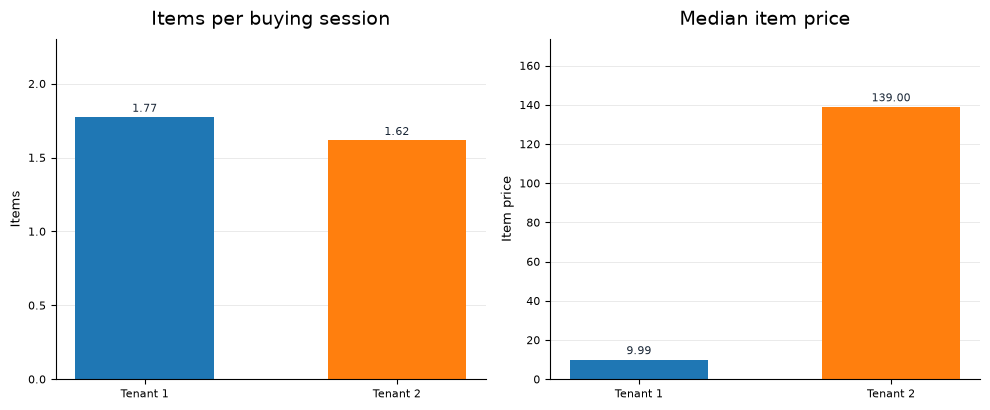

In [9]:
session_flags = load_session_flags()
prices = con.sql("""
SELECT tenant, MEDIAN(item_revenue) AS median_price
FROM events
WHERE event_name = 'purchase' AND item_revenue IS NOT NULL
GROUP BY tenant
ORDER BY tenant
""").df()

items = []
for tenant, frame in session_flags.groupby("tenant", sort=True):
    buyers = frame.loc[frame["purchased"].astype(bool)]
    items.append((tenant, buyers["purchase_rows"].sum() / len(buyers)))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
names = [tenant_name(tenant) for tenant, _ in items]
vals = [value for _, value in items]
bars = axes[0].bar(names, vals, color=[f"C{i}" for i in range(len(items))], width=0.55)
for bar, val in zip(bars, vals):
    point(axes[0], bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{val:.2f}")
axes[0].set_ylim(0, max(vals) * 1.3)
polish(axes[0], "Items per buying session", ylabel="Items")

price_names = [tenant_name(tenant) for tenant in prices["tenant"]]
price_vals = prices["median_price"].tolist()
bars = axes[1].bar(price_names, price_vals, color=[f"C{i}" for i in range(len(price_vals))], width=0.55)
for bar, val in zip(bars, price_vals):
    point(axes[1], bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{val:,.2f}")
axes[1].set_ylim(0, max(price_vals) * 1.25)
polish(axes[1], "Median item price", ylabel="Item price")
fig.tight_layout()
plt.show()


## Inside a tenant, busier days carry that tenant's revenue

Bars are sessions. The line is item revenue for that tenant only. Each tenant keeps the full width, so the fifteen dates and both labels stay readable. Read each chart on its own revenue axis.


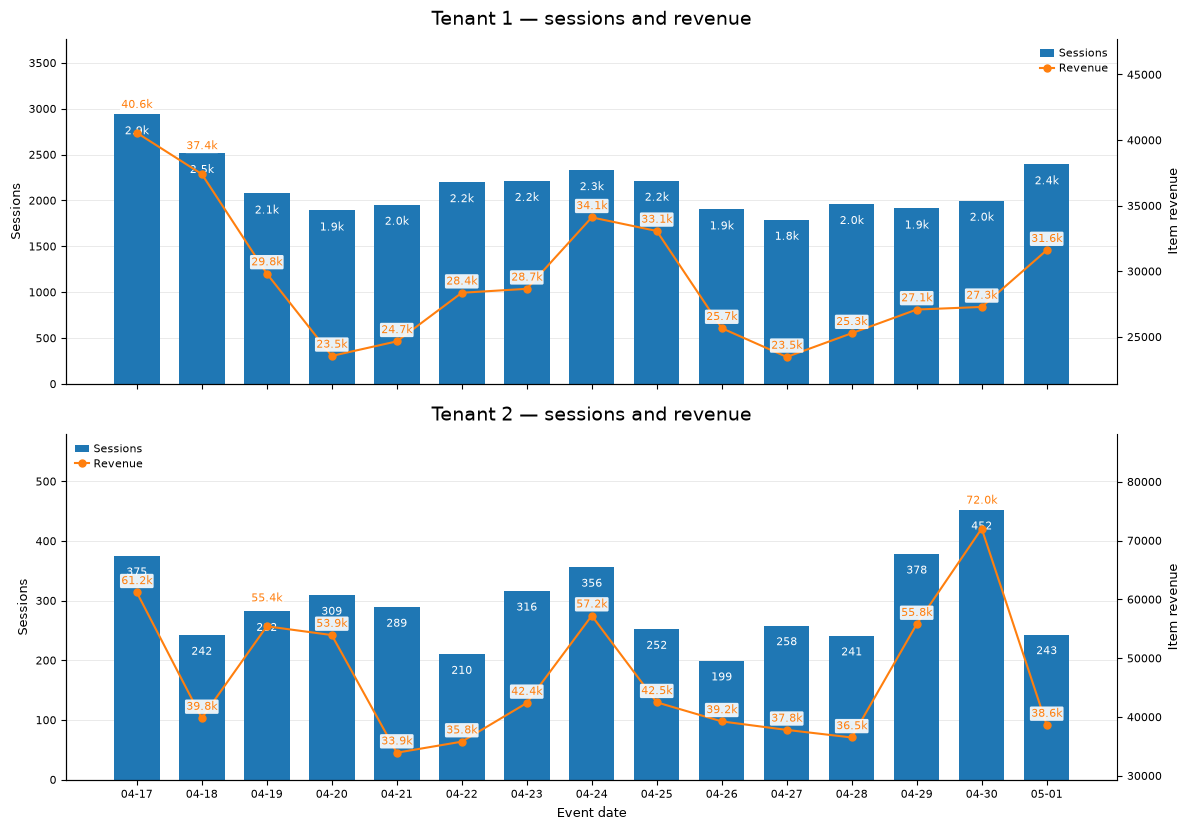

In [10]:
import numpy as np

daily = load_daily()
frame = daily.copy()
frame["day"] = frame["event_date"].dt.normalize()
tenants = list(frame.groupby("tenant", sort=True))
fig, axes = plt.subplots(len(tenants), 1, figsize=(12, 4.2 * len(tenants)), sharex=True)
if len(tenants) == 1:
    axes = [axes]

for ax, (tenant, part) in zip(axes, tenants):
    part = part.sort_values("day")
    x = np.arange(len(part))
    ax.bar(x, part["unique_sessions"], width=0.7, color="C0", label="Sessions")
    ax.set_ylim(0, part["unique_sessions"].max() * 1.28)
    rev = ax.twinx()
    rev.plot(x, part["total_item_revenue"], color="C1", marker="o", markersize=5, label="Revenue")
    low = part["total_item_revenue"].min()
    high = part["total_item_revenue"].max()
    span = high - low
    rev.set_ylim(low - span * 0.12, high + span * 0.42)
    fig.canvas.draw()
    for xpos, sessions, revenue in zip(x, part["unique_sessions"], part["total_item_revenue"]):
        session_px = ax.transData.transform((xpos, sessions))[1]
        revenue_px = rev.transData.transform((xpos, revenue))[1]
        point(
            ax,
            xpos,
            sessions,
            short_num(sessions),
            color="white",
            xytext=(0, -8),
            va="top",
        )
        point(
            rev,
            xpos,
            revenue,
            short_num(revenue),
            color="C1",
            xytext=(0, 16 if abs(session_px - revenue_px) < 22 else 4),
            va="bottom",
            bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.9),
        )
    rev.set_ylabel("Item revenue", fontsize=9)
    rev.tick_params(labelsize=8)
    rev.spines["top"].set_visible(False)
    ax.set_xticks(x)
    ax.set_xticklabels([day.strftime("%m-%d") for day in part["day"]])
    polish(ax, f"{tenant_name(tenant)} — sessions and revenue", ylabel="Sessions", grid="y")
    bars, bar_labels = ax.get_legend_handles_labels()
    lines, line_labels = rev.get_legend_handles_labels()
    peak_x = int(np.argmax(part["unique_sessions"].to_numpy()))
    ax.legend(
        bars + lines,
        bar_labels + line_labels,
        loc="upper left" if peak_x > len(part) / 2 else "upper right",
        **LEGEND,
    )

axes[-1].set_xlabel("Event date", fontsize=9)
fig.tight_layout()
plt.show()


## Stores differ more than the tenants do

The rate is sessions with a purchase, divided by all sessions at the store. The label is that rate and the kiosk count. Both charts share the percent axis. Tenant 2 has two stores, so that chart is the short one at the top. More kiosks are not the higher rate. This is the store table, read by conversion instead of raw revenue.


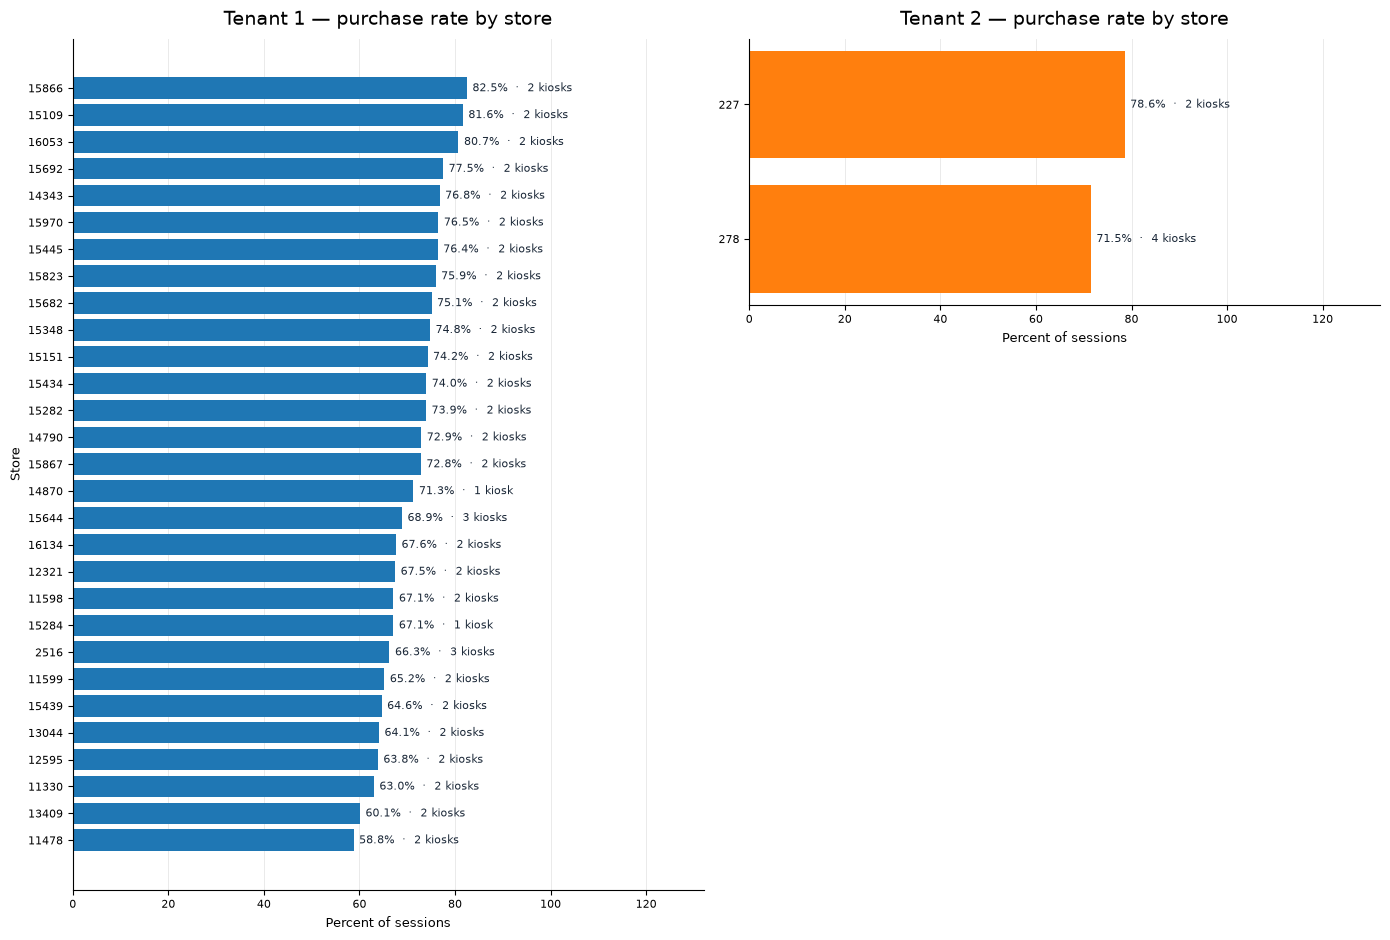

In [11]:
session_flags = load_session_flags()
store = (
    session_flags.groupby(["tenant", "store"], as_index=False)
    .agg(sessions=("session_id", "size"), purchased=("purchased", "sum"), kiosks=("kiosk", "nunique"))
)
store["rate"] = store["purchased"] / store["sessions"]
groups = [
    (tenant, frame.sort_values("rate", ascending=True))
    for tenant, frame in store.groupby("tenant", sort=True)
]
rows = max(len(frame) for _, frame in groups)
fig, axes = plt.subplots(1, len(groups), figsize=(14, 9.5), sharex=True)
if len(groups) == 1:
    axes = [axes]
for ax, (tenant, frame), color in zip(axes, groups, ["C0", "C1"]):
    y = list(range(len(frame)))
    ax.barh(y, frame["rate"] * 100, color=color)
    ax.set_yticks(y)
    ax.set_yticklabels(frame["store"].astype(str))
    for i, (rate, kiosks) in enumerate(zip(frame["rate"], frame["kiosks"])):
        kiosks = int(kiosks)
        noun = "kiosk" if kiosks == 1 else "kiosks"
        point(
            ax,
            rate * 100,
            i,
            f"{rate * 100:.1f}%  ·  {kiosks} {noun}",
            xytext=(4, 0),
            va="center",
            ha="left",
        )
    ax.set_xlim(0, 132)
    polish(
        ax,
        f"{tenant_name(tenant)} — purchase rate by store",
        xlabel="Percent of sessions",
        ylabel="Store" if len(frame) > 5 else None,
        grid="x",
    )
fig.tight_layout()
tall = max(axes, key=lambda ax: len(ax.get_yticks()))
box = tall.get_position()
slot = box.height / rows
for ax, (_, frame) in zip(axes, groups):
    if len(frame) >= rows:
        continue
    pos = ax.get_position()
    height = max(slot * len(frame), 0.28)
    ax.set_position([pos.x0, box.y1 - height, pos.width, height])
plt.show()
